# Experiment No. 5 (Computer Laboratory – I BE AI&DS)

**Aim:**  
Use different voting mechanisms and apply AdaBoost (Adaptive Boosting), Gradient Tree Boosting (GBM), and XGBoost classification on the Iris dataset, and compare the performance of the three models using different evaluation measures.

**Dataset Link:**  
`https://www.kaggle.com/datasets/uciml/iris` (Iris Species Dataset, 150 samples, 4 features).

**Objectives:**  
1. Load and preprocess the Iris dataset (features extraction and label encoding).
2. Implement and train individual boosting models: **AdaBoost**, **Gradient Tree Boosting (GBM)**, and **XGBoost**.
3. Implement ensemble voting mechanisms: **Hard Voting** (majority rule) and **Soft Voting** (predicted probability averaging).
4. Evaluate and compare all models across multiple metrics: **Accuracy**, **Precision**, **Recall**, and **F1-Score**.
5. Visualize the performance comparison using grouped bar charts and detailed classification report.

In [1]:
# Cell 1 - Import Required Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, VotingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

In [2]:
# Cell 2 - Load and Preprocess Iris Dataset
url = "https://raw.githubusercontent.com/plotly/datasets/master/iris.csv"
try:
    df = pd.read_csv("Iris.csv")
except Exception:
    df = pd.read_csv(url)

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows of Iris dataset:")
display(df.head()) if 'display' in globals() else print(df.head())

# Separate features (X) and target label (y)
feature_cols = [c for c in df.columns if c not in ['Id', 'Species', 'Name']]
X = df[feature_cols].values

# Encode categorical class labels to integer values (0, 1, 2)
target_col = 'Species' if 'Species' in df.columns else 'Name'
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df[target_col])

print(f"\nFeatures ({len(feature_cols)}):", feature_cols)
print("Target Classes Mapping:", dict(zip(label_encoder.classes_, range(len(label_encoder.classes_)))))

# Train-Test split (80% training, 20% testing with stratification)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Training Samples: {X_train.shape[0]}, Testing Samples: {X_test.shape[0]}")

Dataset Shape: (150, 6)

First 5 rows of Iris dataset:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa

Features (4): ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
Target Classes Mapping: {'Iris-setosa': 0, 'Iris-versicolor': 1, 'Iris-virginica': 2}
Training Samples: 120, Testing Samples: 30


In [3]:
# Cell 3 - Build and Train Individual Boosting Models
# 1. AdaBoost (Adaptive Boosting)
ada_model = AdaBoostClassifier(n_estimators=50, random_state=42)
ada_model.fit(X_train, y_train)
ada_preds = ada_model.predict(X_test)

# 2. Gradient Tree Boosting (GBM)
gbm_model = GradientBoostingClassifier(n_estimators=50, learning_rate=0.1, random_state=42)
gbm_model.fit(X_train, y_train)
gbm_preds = gbm_model.predict(X_test)

# 3. XGBoost (Extreme Gradient Boosting)
xgb_model = XGBClassifier(n_estimators=50, learning_rate=0.1, eval_metric='mlogloss', random_state=42)
xgb_model.fit(X_train, y_train)
xgb_preds = xgb_model.predict(X_test)

print("All 3 Boosting models trained successfully!")

All 3 Boosting models trained successfully!


In [4]:
# Cell 4 - Apply Different Voting Mechanisms (Hard and Soft Voting)
# 1. Hard Voting: Predicts the class with majority votes from base models
voting_hard = VotingClassifier(
    estimators=[('ada', ada_model), ('gbm', gbm_model), ('xgb', xgb_model)],
    voting='hard'
)
voting_hard.fit(X_train, y_train)
hard_preds = voting_hard.predict(X_test)

# 2. Soft Voting: Averages predicted class probabilities and picks the highest
voting_soft = VotingClassifier(
    estimators=[('ada', ada_model), ('gbm', gbm_model), ('xgb', xgb_model)],
    voting='soft'
)
voting_soft.fit(X_train, y_train)
soft_preds = voting_soft.predict(X_test)

print("Hard and Soft Voting ensemble models trained successfully!")

Hard and Soft Voting ensemble models trained successfully!


In [5]:
# Cell 5 - Performance Evaluation and Comparison Table
models_dict = {
    'AdaBoost': ada_preds,
    'Gradient Boosting (GBM)': gbm_preds,
    'XGBoost': xgb_preds,
    'Hard Voting': hard_preds,
    'Soft Voting': soft_preds
}

results_list = []
for model_name, preds in models_dict.items():
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, average='weighted')
    rec = recall_score(y_test, preds, average='weighted')
    f1 = f1_score(y_test, preds, average='weighted')
    results_list.append({
        'Model': model_name,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4)
    })

comparison_df = pd.DataFrame(results_list)
print("--- Performance Comparison of Boosting Models and Voting Mechanisms ---")
display(comparison_df) if 'display' in globals() else print(comparison_df.to_string(index=False))

--- Performance Comparison of Boosting Models and Voting Mechanisms ---
                  Model  Accuracy  Precision  Recall  F1-Score
               AdaBoost    0.9333     0.9333  0.9333    0.9333
Gradient Boosting (GBM)    0.9667     0.9697  0.9667    0.9666
                XGBoost    0.9667     0.9697  0.9667    0.9666
            Hard Voting    0.9667     0.9697  0.9667    0.9666
            Soft Voting    0.9667     0.9697  0.9667    0.9666


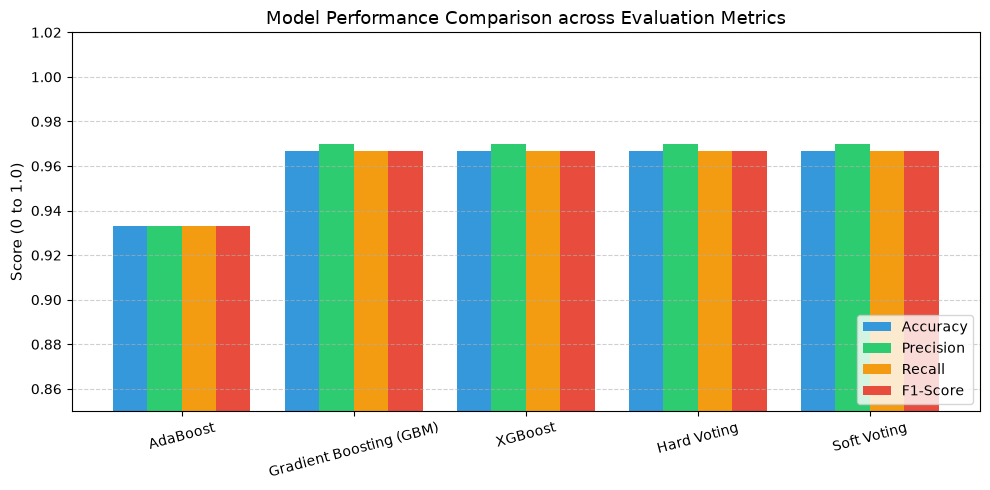


Detailed Classification Report (Soft Voting Ensemble):
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



In [6]:
# Cell 6 - Visualization & Detailed Classification Report
# 1. Grouped Bar Chart comparing evaluation metrics
plt.figure(figsize=(10, 5))
x_pos = np.arange(len(comparison_df))
width = 0.2

plt.bar(x_pos - 1.5*width, comparison_df['Accuracy'], width, label='Accuracy', color='#3498db')
plt.bar(x_pos - 0.5*width, comparison_df['Precision'], width, label='Precision', color='#2ecc71')
plt.bar(x_pos + 0.5*width, comparison_df['Recall'], width, label='Recall', color='#f39c12')
plt.bar(x_pos + 1.5*width, comparison_df['F1-Score'], width, label='F1-Score', color='#e74c3c')

plt.xticks(x_pos, comparison_df['Model'], rotation=15, fontsize=10)
plt.ylabel('Score (0 to 1.0)', fontsize=11)
plt.ylim(0.85, 1.02)
plt.title('Model Performance Comparison across Evaluation Metrics', fontsize=13)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# 2. Detailed Classification Report for Soft Voting
print("\nDetailed Classification Report (Soft Voting Ensemble):")
print(classification_report(y_test, soft_preds, target_names=label_encoder.classes_))